## 1. Import library dan membaca dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# Mencari file dataset (folder data/raw)
kandidat = ["../data/raw/dirty_cafe_sales.csv",
            "data/raw/dirty_cafe_sales.csv",
            "dirty_cafe_sales.csv"]
RAW = next((Path(p) for p in kandidat if Path(p).exists()), None)
if RAW is None:
    raise FileNotFoundError(
        "dirty_cafe_sales.csv tidak ditemukan. Taruh di data/raw/ lalu jalankan ulang.")
RAW = RAW.resolve()

# Folder hasil (data/clean)
CLEAN_DIR = (RAW.parent.parent if RAW.parent.name == "raw" else RAW.parent) / "clean"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(RAW)

print("Lokasi data :", RAW)
print("Ukuran data :", df_raw.shape)
print("Nama kolom  :", list(df_raw.columns))

# Memastikan kolom sesuai dengan yang dipakai di notebook ini
KOLOM_WAJIB = ["Transaction ID", "Item", "Quantity", "Price Per Unit",
               "Total Spent", "Payment Method", "Location", "Transaction Date"]
hilang = [k for k in KOLOM_WAJIB if k not in df_raw.columns]
assert not hilang, f"Kolom tidak ada di dataset: {hilang}. Sesuaikan nama kolom di notebook."

df_raw.head()

Lokasi data : C:\Users\USer\Desktop\Dataset_machine_learning\dirty_cafe_sales.csv
Ukuran data : (10000, 8)
Nama kolom  : ['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 2. Eksplorasi awal

In [2]:
df_raw.info()
print()
print(df_raw.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB

                  count unique             top  freq
Transaction ID    10000  10000     TXN_1961373     1
Item               9667     10           Juice  1171
Quantity           9862      7               5  2013
Price Per Unit     9821      8             3.0  2429
Total Spent        9827     19             6.0   979
Payment Method     7421      5  Digital Wallet  2291
Location           6735      4        Takeaw

## 3. Mengidentifikasi masalah data
Nilai `ERROR` dan `UNKNOWN` adalah data rusak yang tidak terdeteksi oleh `isnull()`, jadi dihitung terpisah.

In [3]:
placeholder = ["ERROR", "UNKNOWN"]

masalah = pd.DataFrame({
    "Kosong (NaN)": df_raw.isnull().sum(),
    "ERROR/UNKNOWN": df_raw.isin(placeholder).sum(),
})
masalah["Total Bermasalah"] = masalah["Kosong (NaN)"] + masalah["ERROR/UNKNOWN"]
masalah["Persentase (%)"] = (masalah["Total Bermasalah"] / len(df_raw) * 100).round(2)
display(masalah)

print("Baris duplikat penuh   :", df_raw.duplicated().sum())
print("Transaction ID duplikat:", df_raw["Transaction ID"].duplicated().sum())

,Kosong (NaN),ERROR/UNKNOWN,Total Bermasalah,Persentase (%)
Transaction ID,0,0,0,0.00
Item,333,636,969,9.69
Quantity,138,341,479,4.79
Price Per Unit,179,354,533,5.33
Total Spent,173,329,502,5.02
Payment Method,2579,599,3178,31.78
Location,3265,696,3961,39.61
Transaction Date,159,301,460,4.60


Baris duplikat penuh   : 0
Transaction ID duplikat: 0


## 4. Data cleaning

### 4.1 Menyalin data dan menyeragamkan nama kolom
Data mentah (`df_raw`) tidak diubah; seluruh perbaikan dilakukan pada salinan `df`.

In [4]:
df = df_raw.copy()
log = [("Data awal", len(df))]

# Nama kolom menjadi huruf kecil dengan underscore
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(list(df.columns))

['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent', 'payment_method', 'location', 'transaction_date']


### 4.2 Merapikan teks dan mengganti `ERROR` / `UNKNOWN` menjadi data kosong

In [5]:
for k in df.select_dtypes(include="object").columns:
    df[k] = df[k].str.strip()

df = df.replace(["ERROR", "UNKNOWN", ""], np.nan)
print("Total sel kosong setelah penggantian:", int(df.isnull().sum().sum()))
df.isnull().sum()

Total sel kosong setelah penggantian: 10082


C:\Users\USer\AppData\Local\Temp\ipykernel_11884\2938767342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for k in df.select_dtypes(include="object").columns:


transaction_id         0
item                 969
quantity             479
price_per_unit       533
total_spent          502
payment_method      3178
location            3961
transaction_date     460
dtype: int64

### 4.3 Memperbaiki tipe data

In [6]:
for k in ["quantity", "price_per_unit", "total_spent"]:
    df[k] = pd.to_numeric(df[k], errors="coerce")

df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")
df.dtypes

transaction_id                 str
item                           str
quantity                   float64
price_per_unit             float64
total_spent                float64
payment_method                 str
location                       str
transaction_date    datetime64[us]
dtype: object

### 4.4 Menghapus duplikat

In [7]:
sebelum = len(df)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="transaction_id")
print("Baris duplikat dihapus:", sebelum - len(df))
log.append(("Hapus duplikat", len(df)))

Baris duplikat dihapus: 0


### 4.5 Melengkapi data kosong dengan aturan logis
Ketiga kolom angka saling berhubungan: `total_spent = quantity × price_per_unit`. Selain itu, setiap menu memiliki harga satuan yang tetap. Data kosong dilengkapi dari hubungan tersebut sebelum menggunakan cara lain.

In [8]:
# (a) Harga satuan per menu = harga yang paling sering muncul
harga_item = (df.dropna(subset=["item", "price_per_unit"])
                .groupby("item")["price_per_unit"]
                .agg(lambda s: s.mode().iloc[0]))
display(harga_item.to_frame("harga_satuan"))

m = df["price_per_unit"].isna() & df["item"].notna()
df.loc[m, "price_per_unit"] = df.loc[m, "item"].map(harga_item)

# (b) Melengkapi dari hubungan total = quantity x harga
m = df["total_spent"].isna() & df["quantity"].notna() & df["price_per_unit"].notna()
df.loc[m, "total_spent"] = df.loc[m, "quantity"] * df.loc[m, "price_per_unit"]

m = df["quantity"].isna() & df["total_spent"].notna() & df["price_per_unit"].notna()
df.loc[m, "quantity"] = df.loc[m, "total_spent"] / df.loc[m, "price_per_unit"]

m = df["price_per_unit"].isna() & df["total_spent"].notna() & df["quantity"].notna()
df.loc[m, "price_per_unit"] = df.loc[m, "total_spent"] / df.loc[m, "quantity"]

# (c) Menu yang kosong ditebak dari harga, hanya jika harga itu milik satu menu saja
ref = df.dropna(subset=["item", "price_per_unit"])
harga_unik = ref.groupby("price_per_unit")["item"].nunique()
harga_unik = harga_unik[harga_unik == 1].index
peta = ref.drop_duplicates("price_per_unit").set_index("price_per_unit")["item"]
m = df["item"].isna() & df["price_per_unit"].isin(harga_unik)
df.loc[m, "item"] = df.loc[m, "price_per_unit"].map(peta)

df["quantity"] = df["quantity"].round()
print("Sel kosong tersisa:")
print(df.isnull().sum())

,harga_satuan
item,
Cake,3.0
Coffee,2.0
Cookie,1.0
Juice,3.0
Salad,5.0
Sandwich,4.0
Smoothie,4.0
Tea,1.5


Sel kosong tersisa:
transaction_id         0
item                 480
quantity              23
price_per_unit         6
total_spent           23
payment_method      3178
location            3961
transaction_date     460
dtype: int64


### 4.6 Menangani data kosong yang tersisa
- Kolom kategori (`item`, `payment_method`, `location`) diisi `Tidak Diketahui` agar baris tidak terbuang.
- Baris yang masih kehilangan `quantity`, `total_spent`, atau `transaction_date` dihapus karena nilainya tidak dapat ditebak dengan wajar.

In [9]:
for k in ["item", "payment_method", "location"]:
    df[k] = df[k].fillna("Tidak Diketahui")

sebelum = len(df)
df = df.dropna(subset=["quantity", "price_per_unit", "total_spent", "transaction_date"])
print("Baris dihapus karena data inti kosong:", sebelum - len(df))
log.append(("Hapus baris data inti kosong", len(df)))

df["quantity"] = df["quantity"].astype(int)
df = df.reset_index(drop=True)

Baris dihapus karena data inti kosong: 486


### 4.7 Validasi hasil cleaning

In [10]:
print("Total sel kosong :", int(df.isnull().sum().sum()))
print("Duplikat         :", int(df.duplicated().sum()))

selisih = (df["quantity"] * df["price_per_unit"] - df["total_spent"]).abs()
print("Baris total_spent tidak sama dengan quantity x harga:", int((selisih > 0.01).sum()))
print("Baris dengan nilai <= 0:",
      int((df[["quantity", "price_per_unit", "total_spent"]] <= 0).any(axis=1).sum()))

# Pemeriksaan outlier (IQR). Hanya dilaporkan, tidak dihapus karena harga menu tetap.
for k in ["quantity", "price_per_unit", "total_spent"]:
    q1, q3 = df[k].quantile([0.25, 0.75])
    batas = 1.5 * (q3 - q1)
    n_out = ((df[k] < q1 - batas) | (df[k] > q3 + batas)).sum()
    print(f"Outlier IQR pada {k}: {n_out}")

df.describe(include="all").T

Total sel kosong : 0
Duplikat         : 0
Baris total_spent tidak sama dengan quantity x harga: 0
Baris dengan nilai <= 0: 0
Outlier IQR pada quantity: 0
Outlier IQR pada price_per_unit: 0
Outlier IQR pada total_spent: 259


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,9514,9514,TXN_1961373,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item,9514,9,Coffee,1241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,9514.0,NaN,NaN,NaN,3.021232,1.0,2.0,3.0,4.0,5.0,1.420285
price_per_unit,9514.0,NaN,NaN,NaN,2.94855,1.0,2.0,3.0,4.0,5.0,1.279259
total_spent,9514.0,NaN,NaN,NaN,8.92038,1.0,4.0,8.0,12.0,25.0,6.003809
payment_method,9514,4,Tidak Diketahui,3005,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,9514,3,Tidak Diketahui,3770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,9514,NaN,NaN,NaN,2023-07-01 23:14:35.593861,2023-01-01 00:00:00,2023-04-01 00:00:00,2023-07-02 00:00:00,2023-10-02 00:00:00,2023-12-31 00:00:00,NaN


## 5. Data transformation

### 5.1 Fitur baru dari tanggal

In [11]:
df["tahun"] = df["transaction_date"].dt.year
df["bulan"] = df["transaction_date"].dt.month
df["hari"] = df["transaction_date"].dt.day_name()
df["akhir_pekan"] = df["transaction_date"].dt.dayofweek.isin([5, 6]).astype(int)
df[["transaction_date", "tahun", "bulan", "hari", "akhir_pekan"]].head()

,transaction_date,tahun,bulan,hari,akhir_pekan
0,2023-09-08,2023,9,Friday,0
1,2023-05-16,2023,5,Tuesday,0
2,2023-07-19,2023,7,Wednesday,0
3,2023-04-27,2023,4,Thursday,0
4,2023-06-11,2023,6,Sunday,1


### 5.2 Binning: mengelompokkan total belanja
Batas kelompok dapat disesuaikan dengan sebaran data.

In [12]:
df["kategori_belanja"] = pd.cut(
    df["total_spent"],
    bins=[0, 5, 10, float("inf")],
    labels=["Rendah", "Sedang", "Tinggi"],
)
df["kategori_belanja"].value_counts()

kategori_belanja
Rendah    3487
Tinggi    3118
Sedang    2909
Name: count, dtype: int64

### 5.3 Scaling pada `total_spent`

In [13]:
mn, mx = df["total_spent"].min(), df["total_spent"].max()
df["total_spent_minmax"] = (df["total_spent"] - mn) / (mx - mn)
df["total_spent_zscore"] = (df["total_spent"] - df["total_spent"].mean()) / df["total_spent"].std()
df[["total_spent", "total_spent_minmax", "total_spent_zscore"]].describe().round(3)

,total_spent,total_spent_minmax,total_spent_zscore
count,9514.000,9514.000,9514.000
mean,8.920,0.330,-0.000
std,6.004,0.250,1.000
min,1.000,0.000,-1.319
25%,4.000,0.125,-0.820
50%,8.000,0.292,-0.153
75%,12.000,0.458,0.513
max,25.000,1.000,2.678


### 5.4 One-Hot Encoding
Kolom kategori diubah menjadi kolom biner (0/1) sehingga siap dipakai model machine learning.

In [14]:
df_transformed = pd.get_dummies(
    df.drop(columns=["transaction_id", "transaction_date"]),
    columns=["item", "payment_method", "location", "hari", "kategori_belanja"],
    dtype=int,
)
print("Ukuran sebelum encoding:", df.shape)
print("Ukuran sesudah encoding:", df_transformed.shape)
df_transformed.head()

Ukuran sebelum encoding: (9514, 15)
Ukuran sesudah encoding: (9514, 34)


,quantity,price_per_unit,total_spent,tahun,bulan,akhir_pekan,total_spent_minmax,total_spent_zscore,item_Cake,item_Coffee,item_Cookie,item_Juice,item_Salad,item_Sandwich,item_Smoothie,item_Tea,item_Tidak Diketahui,payment_method_Cash,payment_method_Credit Card,payment_method_Digital Wallet,payment_method_Tidak Diketahui,location_In-store,location_Takeaway,location_Tidak Diketahui,hari_Friday,hari_Monday,hari_Saturday,hari_Sunday,hari_Thursday,hari_Tuesday,hari_Wednesday,kategori_belanja_Rendah,kategori_belanja_Sedang,kategori_belanja_Tinggi
0,2,2.0,4.0,2023,9,0,0.125000,-0.819543,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0
1,4,3.0,12.0,2023,5,0,0.458333,0.512944,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1
2,4,1.0,4.0,2023,7,0,0.125000,-0.819543,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0
3,2,5.0,10.0,2023,4,0,0.375000,0.179822,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,1,0
4,2,2.0,4.0,2023,6,1,0.125000,-0.819543,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0


### 5.5 Agregasi untuk menjawab pertanyaan analisis

In [15]:
per_item = (df.groupby("item")
              .agg(jumlah_transaksi=("transaction_id", "count"),
                   total_terjual=("quantity", "sum"),
                   total_pendapatan=("total_spent", "sum"))
              .sort_values("total_pendapatan", ascending=False))
display(per_item)

display(pd.pivot_table(df, values="total_spent", index="item", columns="location",
                       aggfunc="sum", fill_value=0))

,jumlah_transaksi,total_terjual,total_pendapatan
item,,,
Salad,1214,3644,18220.0
Sandwich,1071,3267,13068.0
Smoothie,1046,3194,12776.0
Juice,1121,3341,10023.0
Cake,1081,3278,9834.0
Coffee,1241,3766,7532.0
Tea,1141,3441,5161.5
Tidak Diketahui,450,1386,4827.0
Cookie,1149,3427,3427.0


location,In-store,Takeaway,Tidak Diketahui
item,,,
Cake,2817.0,3003.0,4014.0
Coffee,2066.0,2334.0,3132.0
Cookie,1043.0,1170.0,1214.0
Juice,3168.0,2778.0,4077.0
Salad,5840.0,5445.0,6935.0
Sandwich,4344.0,3968.0,4756.0
Smoothie,3616.0,3536.0,5624.0
Tea,1585.5,1573.5,2002.5
Tidak Diketahui,1372.0,1579.0,1876.0


## 6. Visualisasi sebelum dan sesudah

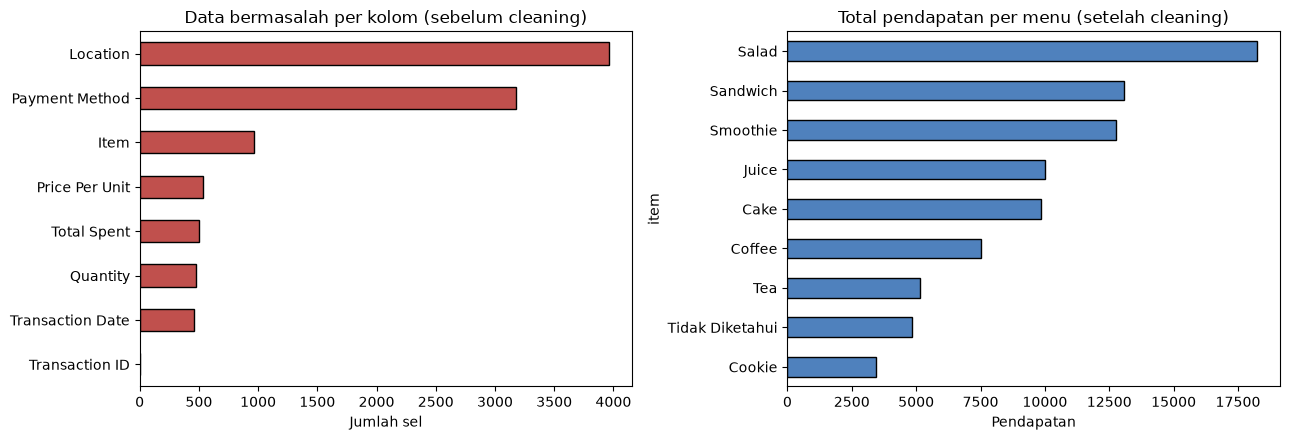

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

masalah["Total Bermasalah"].sort_values().plot.barh(ax=ax[0], color="#C0504D", edgecolor="black")
ax[0].set_title("Data bermasalah per kolom (sebelum cleaning)")
ax[0].set_xlabel("Jumlah sel")

per_item["total_pendapatan"].sort_values().plot.barh(ax=ax[1], color="#4F81BD", edgecolor="black")
ax[1].set_title("Total pendapatan per menu (setelah cleaning)")
ax[1].set_xlabel("Pendapatan")

plt.tight_layout()
plt.show()

## 7. Ringkasan sebelum dan sesudah

In [17]:
ringkasan = pd.DataFrame({
    "Sebelum": [len(df_raw), df_raw.shape[1],
                int(df_raw.isnull().sum().sum() + df_raw.isin(placeholder).sum().sum())],
    "Sesudah": [len(df), df.shape[1], int(df.isnull().sum().sum())],
}, index=["Jumlah baris", "Jumlah kolom", "Sel kosong / ERROR / UNKNOWN"])
display(ringkasan)

display(pd.DataFrame(log, columns=["Langkah", "Jumlah baris"]))

,Sebelum,Sesudah
Jumlah baris,10000,9514
Jumlah kolom,8,15
Sel kosong / ERROR / UNKNOWN,10082,0


,Langkah,Jumlah baris
0,Data awal,10000
1,Hapus duplikat,10000
2,Hapus baris data inti kosong,9514


## 8. Menyimpan hasil

In [18]:
df.to_csv(CLEAN_DIR / "dirty_cafe_sales_clean.csv", index=False)
df_transformed.to_csv(CLEAN_DIR / "dirty_cafe_sales_transformed.csv", index=False)

print("Tersimpan di:", CLEAN_DIR)
print([p.name for p in CLEAN_DIR.iterdir()])

Tersimpan di: C:\Users\USer\Desktop\Dataset_machine_learning\clean
['dirty_cafe_sales_clean.csv', 'dirty_cafe_sales_transformed.csv']
